# PCB 정상/불량 이진 분류 — 개별 패치

기존 `sample.ipynb`의 6종 유형 분류와 별도로 진행하는 실험입니다. 사용자가 선택한 입력은 **잘라낸 개별 회로 패치**입니다.

- 라벨: `0=normal(정상)`, `1=defect(불량)`; 불량 6종은 모두 1로 합칩니다.
- 정상은 정상 기준 영상의 동일 위치 Crop과 검사 영상의 주석된 불량을 피한 회로 Crop을 함께 사용합니다.
- 같은 원본의 정상/불량/기준 영상 패치는 항상 같은 split입니다. 기존 그룹 검증 `group00041`을 유지합니다.
- 공식 test는 전처리와 학습에서 읽지 않습니다. 이번에 보고하는 성능은 validation입니다.
- 목표: 고정 임계값 0.5의 validation Macro F1 0.90 이상을 지향하되 보장하지 않습니다. 불량 Recall과 정상 오탐률도 함께 확인합니다.
- CNN의 sigmoid 점수는 보정된 실제 불량 확률이 아닙니다. 전체 PCB의 위치 탐지/전수 검사 성능은 평가하지 않습니다.

In [4]:
# 현재 Python 환경과 기존에 검증한 Metal 회피 설정을 사용합니다.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display, Image as DisplayImage, Markdown
from src.runtime import configure_runtime

ROOT = Path.cwd()
assert (ROOT / 'data/split/sources.csv').exists(), '프로젝트 루트에서 실행하세요.'
runtime = configure_runtime()
print('Python:', sys.version)
print('TensorFlow:', tf.__version__, 'NumPy:', np.__version__)
print('실행 설정:', runtime)

Python: 3.11.9 (main, Aug 14 2024, 04:17:21) [Clang 18.1.8 ]
TensorFlow: 2.18.1 NumPy: 2.0.2
실행 설정: {'optimizer_options': {'disable_model_pruning': False, 'disable_meta_optimizer': True}, 'gpu_devices': ["PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')"]}


## 데이터 생성과 라벨 감사

128×128 grayscale, bbox 주변 여백 16px, edge padding 규약을 재사용합니다. 검사 영상의 정상 후보는 모든 bbox에서 8px 이상 떨어진 영역으로 제한하고, 빈 배경만 학습하지 않도록 흑/백 회로 패턴이 포함된 영역을 뽑습니다. 주석 밖 정상 후보는 데이터셋 주석이 완전하다는 가정에 따릅니다.

동일 픽셀의 라벨 충돌과 split 간 중복은 격리하고 split 내부 반복은 한 번만 유지합니다. 격리 사유와 생성 실패는 별도 CSV에 기록합니다. 학습 성능을 보기 전에 이 규칙을 고정합니다.

{
  "candidates": 20588,
  "included": 19751,
  "excluded": 837,
  "exclusions": {
    "identical_pixels_across_splits": 837
  },
  "counts": [
    {
      "split": "train",
      "kind": "defect",
      "target": 1,
      "patches": 5338
    },
    {
      "split": "train",
      "kind": "template_matched",
      "target": 0,
      "patches": 4690
    },
    {
      "split": "train",
      "kind": "tested_clear",
      "target": 0,
      "patches": 5308
    },
    {
      "split": "val",
      "kind": "defect",
      "target": 1,
      "patches": 1535
    },
    {
      "split": "val",
      "kind": "template_matched",
      "target": 0,
      "patches": 1346
    },
    {
      "split": "val",
      "kind": "tested_clear",
      "target": 0,
      "patches": 1534
    }
  ],
  "sampling_failures": 31,
  "train_sources": 800,
  "val_sources": 200,
  "test_patches_created": 0,
  "cross_split_group_overlap": 0,
  "cross_split_pixel_overlap": 0,
  "manifest_sha256": "b097c1f2cb6d1e3b6756ef

label,defect,normal
split,,
train,5338,9998
val,1535,2880


kind,defect,template_matched,tested_clear
split,,,
train,5338,4690,5308
val,1535,1346,1534


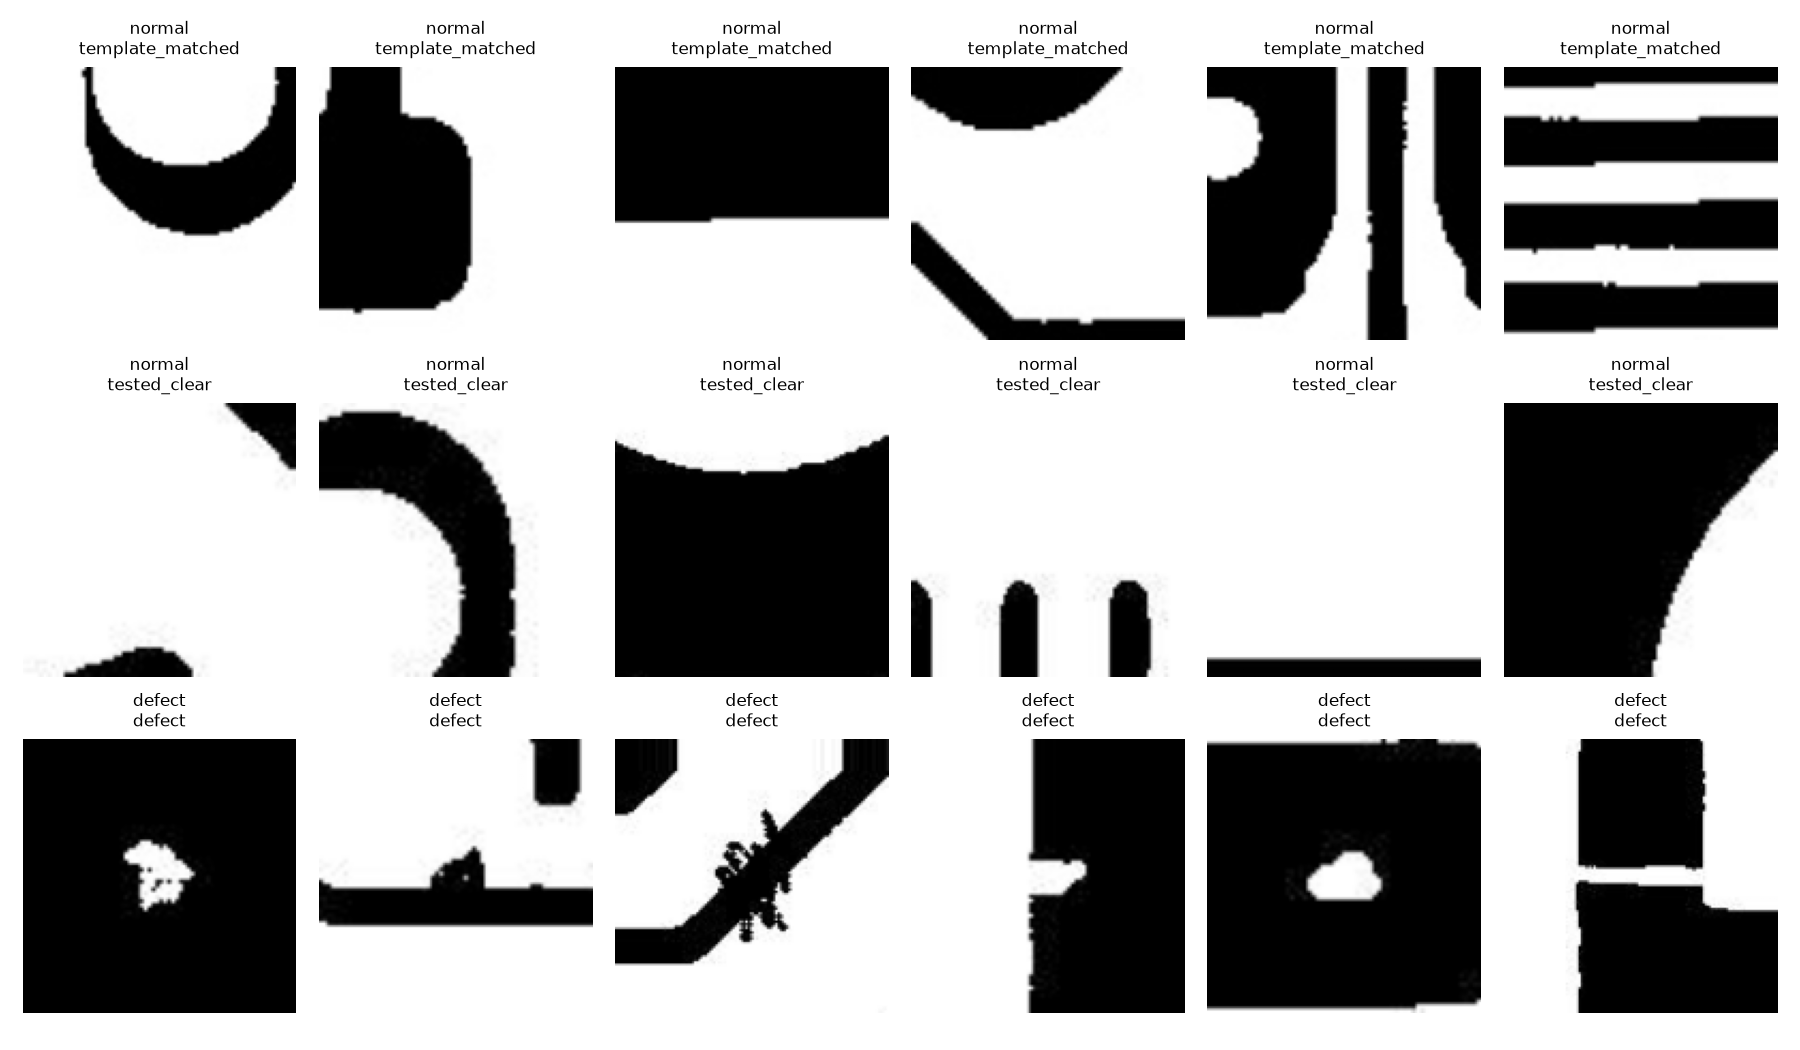

In [5]:
# 원본과 6종 분류 산출물은 읽기만 하고 binary_v1 폴더에 새로 저장합니다.
from src.binary_data import prepare_binary_data
binary_summary = prepare_binary_data(ROOT)
binary_frame = pd.read_csv(ROOT / 'data/split/binary_v1/patches.csv')
display(pd.crosstab(binary_frame['split'], binary_frame['label']))
display(pd.crosstab(binary_frame['split'], binary_frame['kind']))
display(DisplayImage(filename=str(ROOT / 'results/binary/data_examples.png'), width=1000))

## CNN 학습 — 정상 0 / 불량 1

기존 6종 모델의 가중치를 가져오지 않고, Conv 블록(16→32→64)과 BatchNormalization, Dropout, Dense64, Sigmoid 출력 1개를 직접 구성해 새로 학습합니다.

- Adam 0.0005, batch 32, 최대 25 epoch, EarlyStopping patience 6, seed 42.
- 클래스 가중치는 train의 정상/불량 수로만 계산합니다.
- 증강은 train에만 회전·반전·약한 밝기 조절을 적용합니다.
- 검증 Macro F1로 최고 checkpoint를 저장하며 판정 임계값은 0.5로 고정합니다.
- 불량 Recall과 정상 오탐률을 매 epoch 기록하고, graph/eager Accuracy가 다르면 중단합니다.
- 아래 셀은 실제 학습을 실행합니다. 같은 설정으로 완료된 run은 재사용합니다.

In [6]:
# 6종 분류와 독립된 모델·로그·checkpoint를 생성합니다.
from src.binary_train import BinaryTrainingConfig, train_binary_model

binary_config = BinaryTrainingConfig(run_name='binary_cnn_001', epochs=25, batch_size=32,
                                     learning_rate=0.0005, patience=6, seed=42, augment=True, threshold=0.5)
binary_result = train_binary_model(ROOT, binary_config)
display(binary_result)

완료된 이진 분류 결과를 재사용합니다: binary_cnn_001


{'run_name': 'binary_cnn_001',
 'status': 'completed',
 'metrics': {'samples': 4415,
  'accuracy': 0.9886749716874292,
  'balanced_accuracy': 0.9888854958378575,
  'defect_precision': 0.9781068898905344,
  'defect_recall': 0.9895765472312703,
  'defect_f1': 0.9838082901554405,
  'macro_f1': 0.9875502614134917,
  'normal_false_positive_rate': 0.011805555555555555,
  'defect_false_negative_rate': 0.010423452768729642,
  'roc_auc': 0.9985226655808903,
  'average_precision': 0.9968485803543633,
  'true_normal': 2846,
  'false_defect': 34,
  'missed_defect': 16,
  'true_defect': 1519,
  'threshold': 0.5,
  'split': 'validation',
  'official_test_evaluated': False},
 'best_epoch': 12,
 'epochs_completed': 18,
 'elapsed_seconds': 667.6141915839398,
 'model_path': '/Users/yeongjunna/DNN_project/models/binary_cnn_001/best.keras'}

## 저장 checkpoint 검증 및 독립 추론

최고 모델을 파일에서 다시 불러와 성능을 측정합니다. CPU에서 validation 전체를 다시 추론해 Metal 결과와 비교하고, 학습 코드와 분리된 `src/binary_predict.py`도 확인합니다. 원래 6종별 불량 Recall과 정상 출처별 오탐률을 함께 살펴봅니다.

In [7]:
# 저장한 validation 예측과 CPU 전체 추론을 비교합니다.
from tensorflow import keras
from src.binary_train import make_binary_dataset
from src.binary_evaluate import collect_binary_predictions, binary_scores
from src.binary_predict import predict_binary_patch
from PIL import Image as PILImage

BINARY_RUN = 'binary_cnn_001'
BINARY_OUTPUT = ROOT / 'results/binary' / BINARY_RUN
BINARY_MODEL = ROOT / 'models' / BINARY_RUN / 'best.keras'
validation_data, validation_frame = make_binary_dataset(ROOT, 'val', batch_size=32)
stored_predictions = pd.read_csv(BINARY_OUTPUT / 'validation_predictions.csv')
with tf.device('/CPU:0'):
    cpu_model = keras.models.load_model(BINARY_MODEL, compile=False)
    cpu_labels, cpu_scores = collect_binary_predictions(cpu_model, validation_data)
    cpu_device = cpu_model(next(iter(validation_data))[0], training=False).device
assert np.array_equal(cpu_labels, stored_predictions.target.values)
cpu_gpu_delta = float(abs(cpu_scores-stored_predictions.sigmoid_score.values).max())
label_agreement = float(((cpu_scores > 0.5).astype(int) == stored_predictions.predicted_target.values).mean())
assert cpu_gpu_delta < 1e-4 and label_agreement == 1.0

# 각 출처의 사전순 첫 표본으로 확인하며 정답 여부로 예시를 선택하지 않습니다.
independent_examples = []
inference_deltas = []
for kind, subset in stored_predictions.groupby('kind', sort=True):
    row = subset.iloc[0]
    with PILImage.open(ROOT / row.patch_path) as image:
        prediction = predict_binary_patch(BINARY_MODEL, image)
    inference_deltas.append(abs(prediction['sigmoid_score']-float(row.sigmoid_score)))
    independent_examples.append(dict(kind=kind, true_label=row.label, **prediction))
assert max(inference_deltas) < 1e-4
verification = dict(cpu_samples=len(cpu_labels), cpu_device=cpu_device,
                    max_cpu_gpu_delta=cpu_gpu_delta, label_agreement=label_agreement,
                    max_inference_delta=float(max(inference_deltas)),
                    cpu_metrics=binary_scores(cpu_labels, cpu_scores), verified=True)
(ROOT / 'results/binary/inference_verification.json').write_text(json.dumps(verification, indent=2))
display(verification)
display(pd.DataFrame(independent_examples))

{'cpu_samples': 4415,
 'cpu_device': '/job:localhost/replica:0/task:0/device:CPU:0',
 'max_cpu_gpu_delta': 1.1018902588144641e-06,
 'label_agreement': 1.0,
 'max_inference_delta': 3.6743164066876943e-09,
 'cpu_metrics': {'samples': 4415,
  'accuracy': 0.9886749716874292,
  'balanced_accuracy': 0.9888854958378575,
  'defect_precision': 0.9781068898905344,
  'defect_recall': 0.9895765472312703,
  'defect_f1': 0.9838082901554405,
  'macro_f1': 0.9875502614134917,
  'normal_false_positive_rate': 0.011805555555555555,
  'defect_false_negative_rate': 0.010423452768729642,
  'roc_auc': 0.9985228917842924,
  'average_precision': 0.9968500719399479,
  'true_normal': 2846,
  'false_defect': 34,
  'missed_defect': 16,
  'true_defect': 1519,
  'threshold': 0.5},
 'verified': True}

,kind,true_label,target,label,korean,sigmoid_score,threshold,interpretation
0,defect,defect,1,defect,불량,9.999990e-01,0.5,보정되지 않은 모델 점수이며 실제 불량 발생 확률이나 정확도가 아닙니다.
1,template_matched,normal,0,normal,정상,4.599744e-08,0.5,보정되지 않은 모델 점수이며 실제 불량 발생 확률이나 정확도가 아닙니다.
2,tested_clear,normal,0,normal,정상,3.216754e-08,0.5,보정되지 않은 모델 점수이며 실제 불량 발생 확률이나 정확도가 아닙니다.


,model,split,official_test_evaluated,samples,accuracy,balanced_accuracy,defect_precision,defect_recall,defect_f1,macro_f1,normal_false_positive_rate,defect_false_negative_rate,roc_auc,average_precision,true_normal,false_defect,missed_defect,true_defect,threshold
0,Always normal,validation,False,4415,0.652322,0.500000,0.000000,0.000000,0.000000,0.394791,0.000000,1.000000,0.500000,0.347678,2880,0,1535,0,0.5
1,binary_cnn_001,validation,False,4415,0.988675,0.988885,0.978107,0.989577,0.983808,0.987550,0.011806,0.010423,0.998523,0.996849,2846,34,16,1519,0.5


,kind,samples,normal_false_positive_rate
0,template_matched,1346,0.013373
1,tested_clear,1534,0.010430


,class_id,defect_type,samples,recall
0,1,Open Circuit,278,0.992806
1,2,Short Circuit,203,0.965517
2,3,Mousebite,347,1.000000
3,4,Spur,254,0.988189
4,5,Spurious Copper,232,1.000000
5,6,Pin Hole,221,0.981900


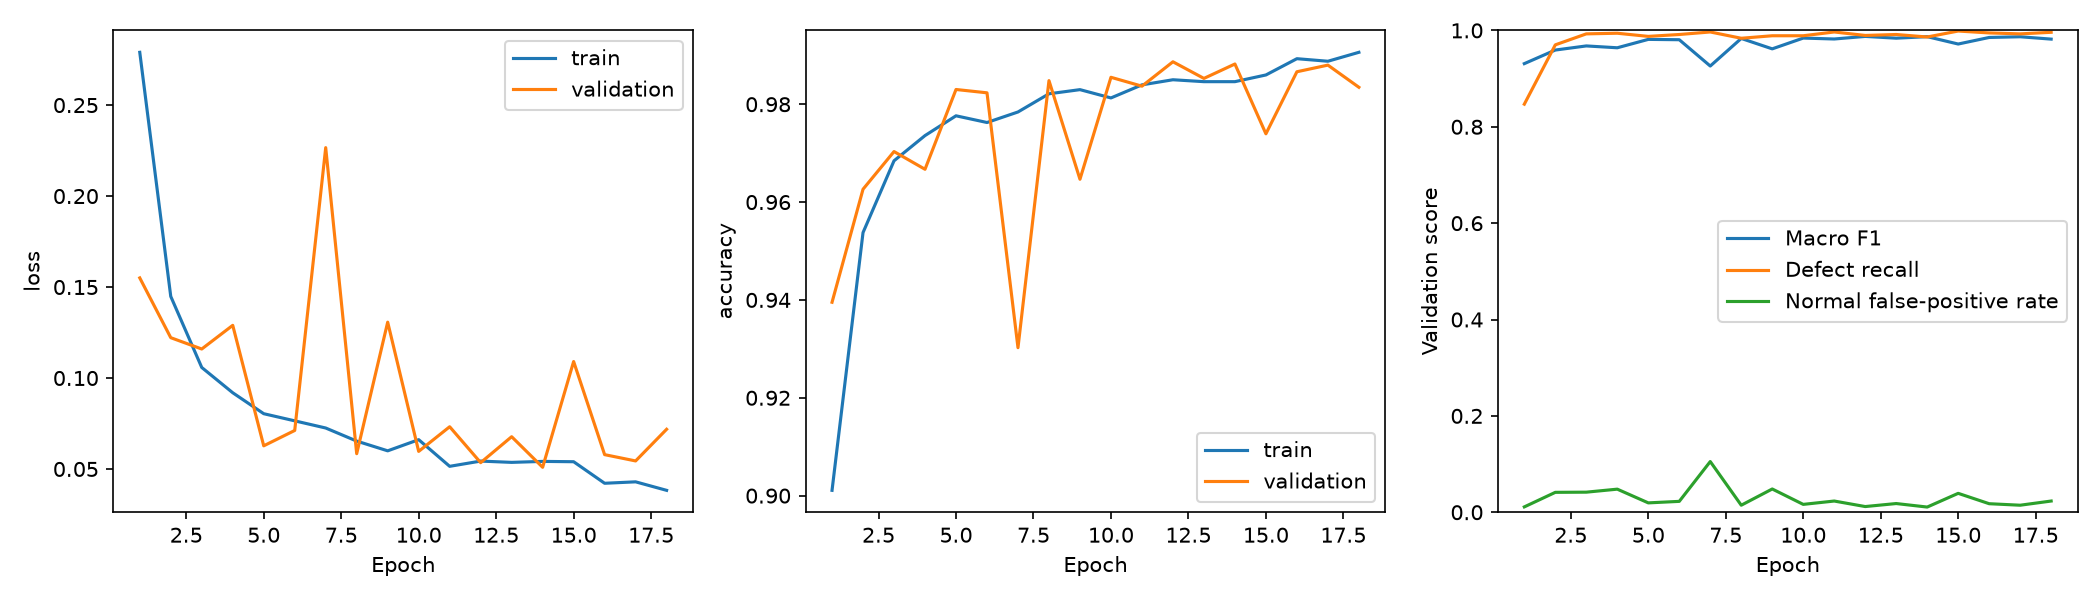

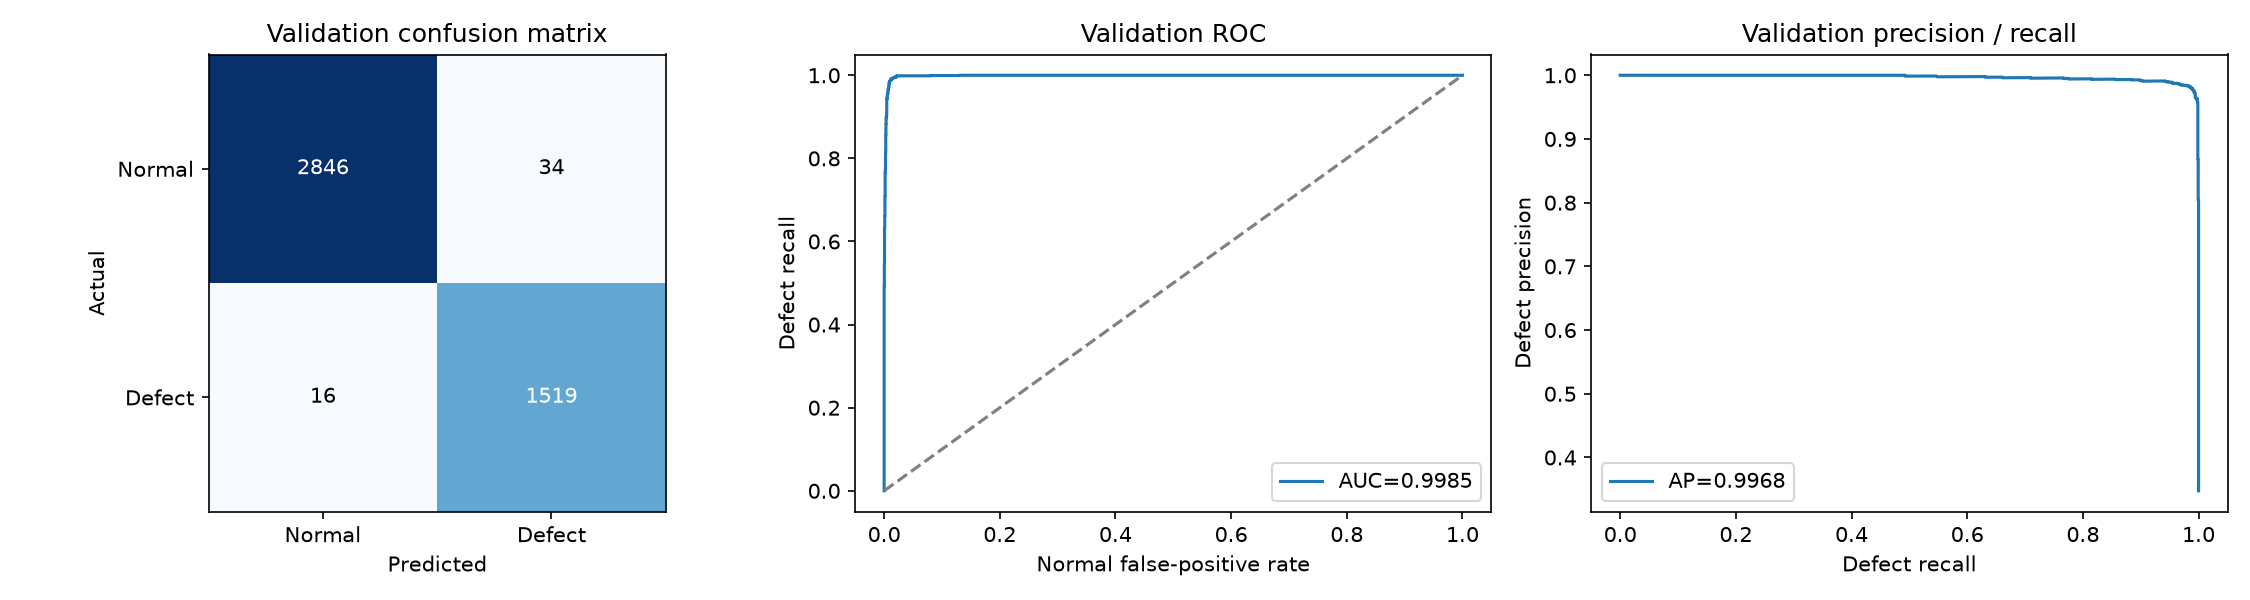

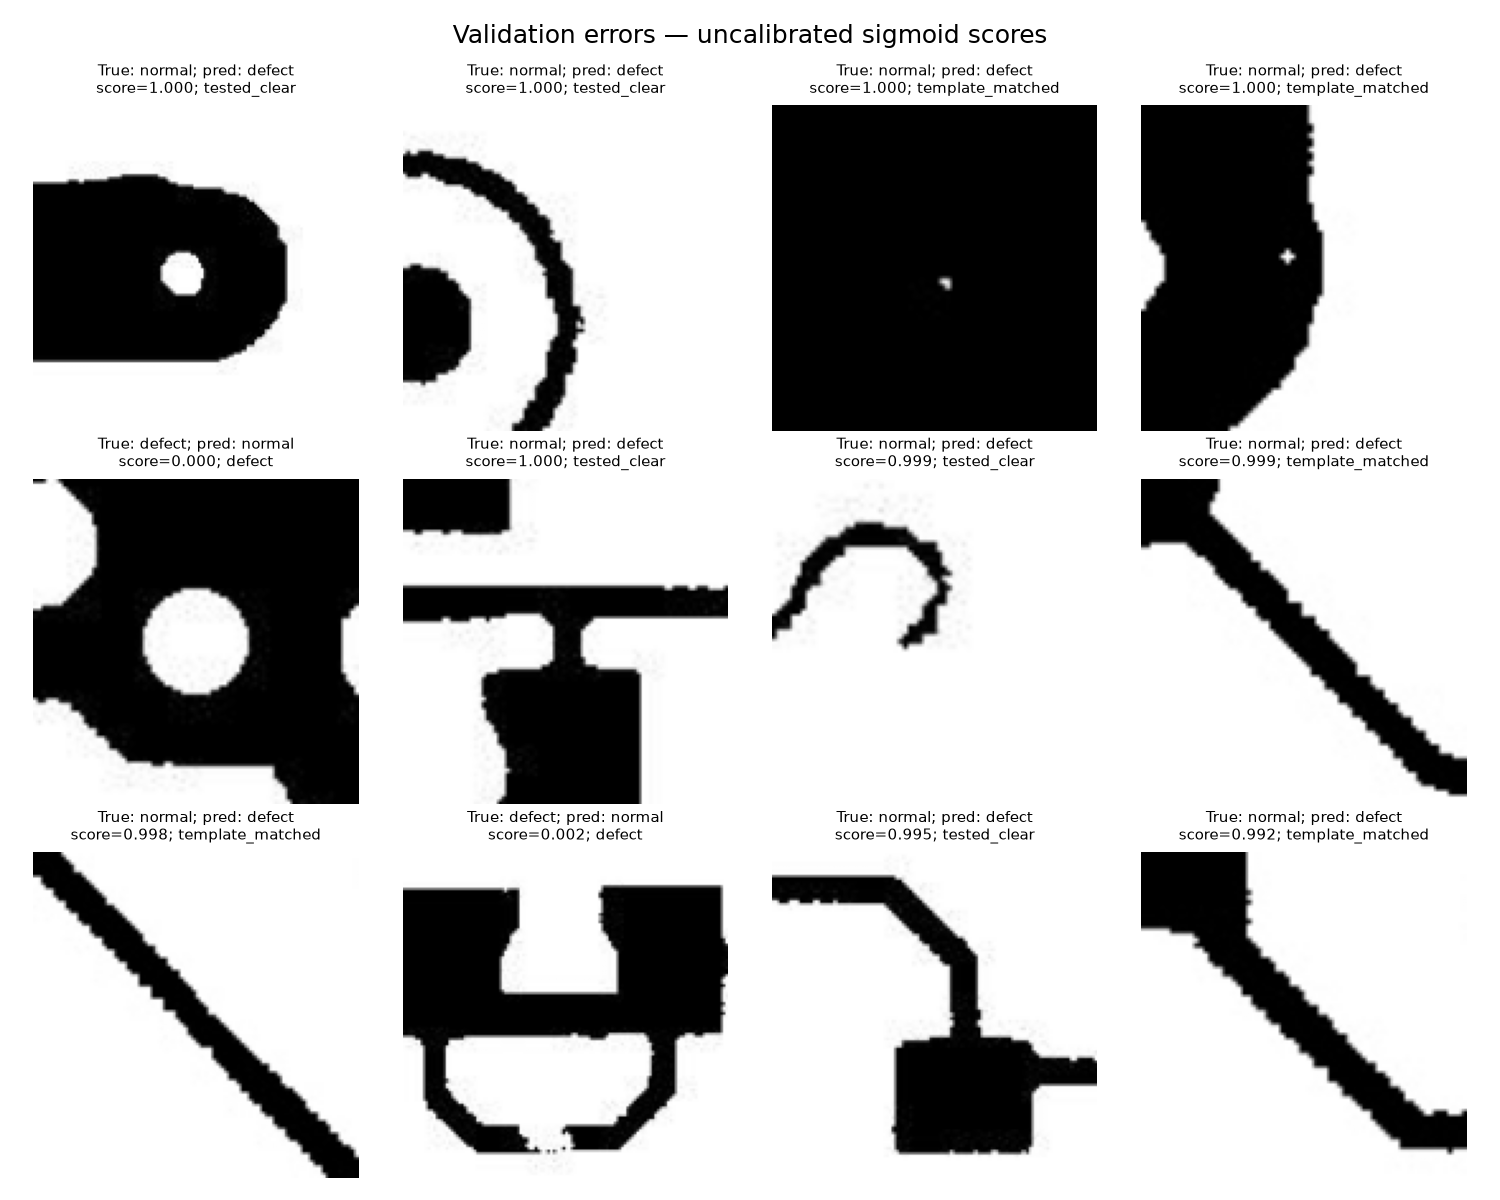

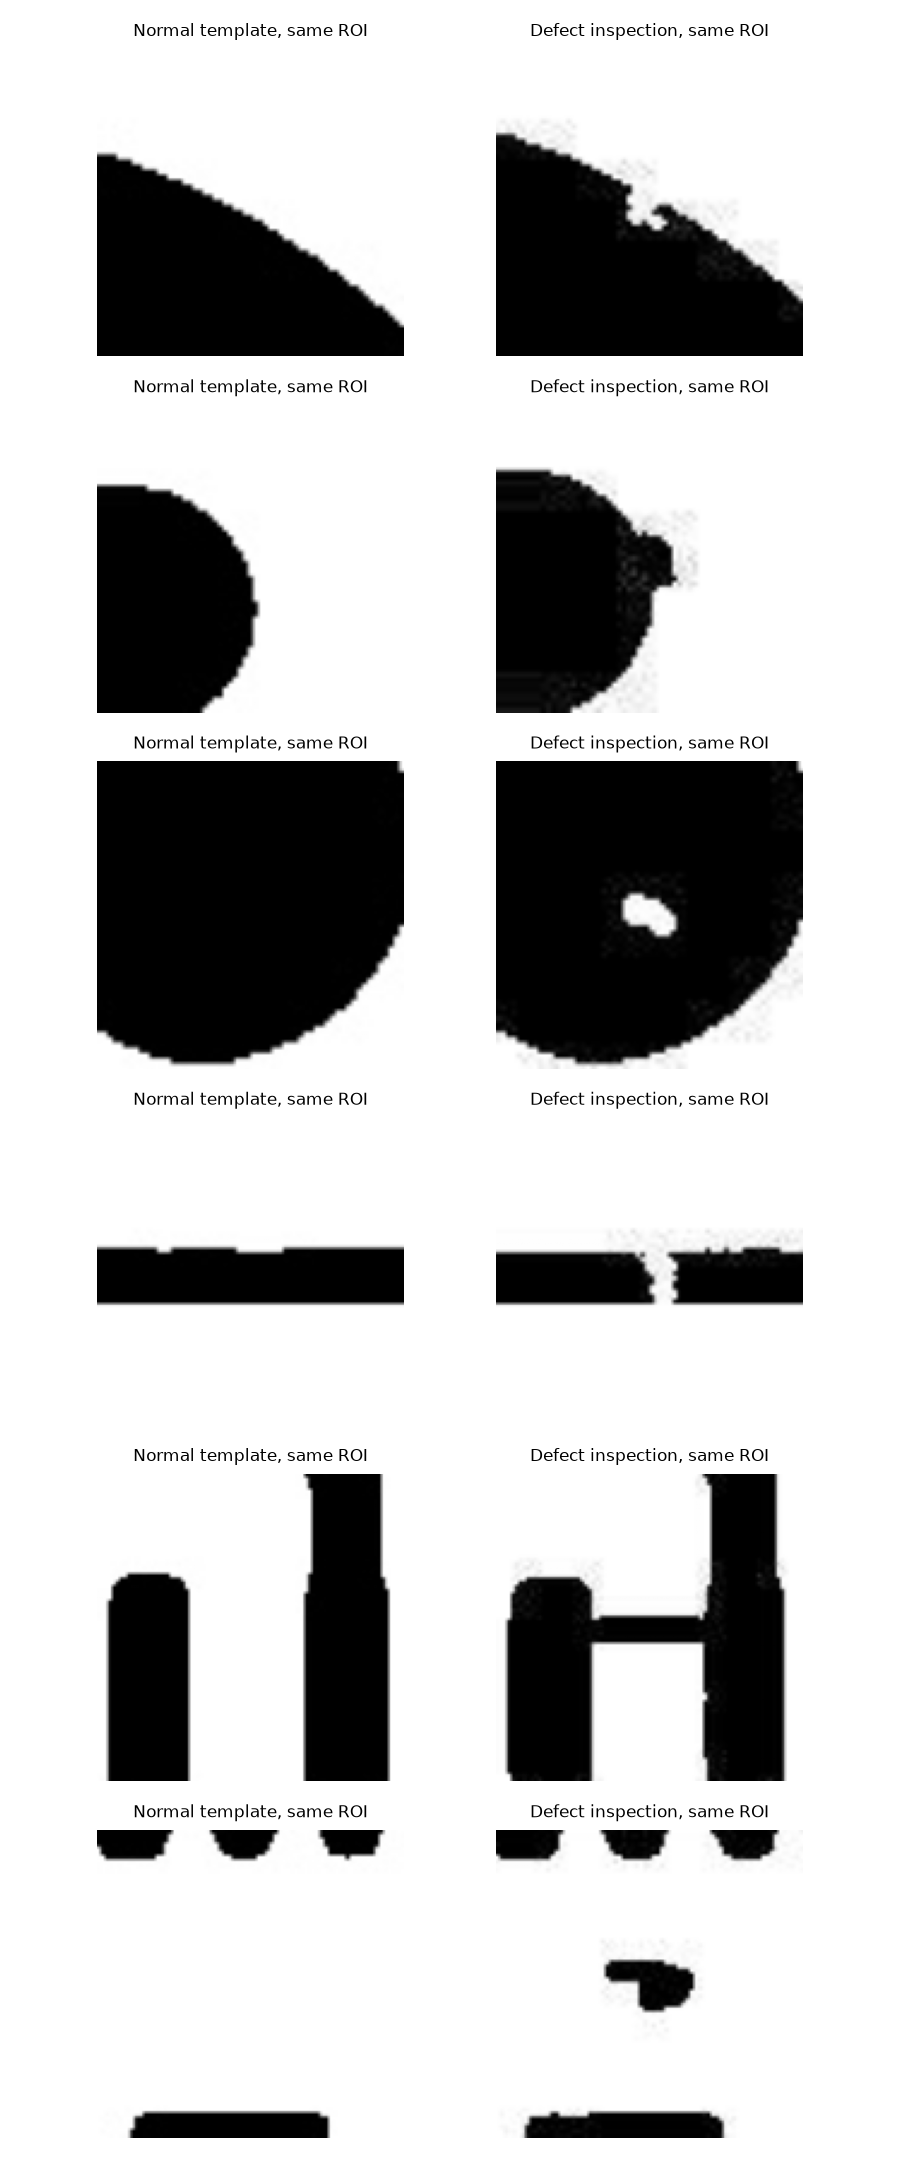

# PCB 개별 패치 정상/불량 분류 결과

## 목적 및 입력

`binary_classification.ipynb`에서 기존 6종 분류와 별도로 실행했다. 입력은 사용자가 선택한
128×128 개별 회로 패치다. `0=normal`, `1=defect`이며 기존 6종 불량을 모두 불량 1로 합쳤다.
정상 기준 영상을 추론 입력으로 요구하지 않는 단일 이미지 CNN이다. 전체 PCB의 불량 위치 탐지나
전체 이미지에 결함이 있는지의 성능은 이번에 평가하지 않았다.

## 데이터 생성과 누수 방지

기존 `sample.ipynb`, 원본, 6종 모델은 변경하지 않고 `binary_v1` 및 별도 모델/결과 폴더를 사용했다.
기존 train 800개/validation 200개 원본 그룹 분할과 검증 그룹 `group00041`을 그대로 유지했다.
같은 원본의 정상/불량/템플릿 패치는 분할을 넘지 않는다. 공식 test는 읽거나 Crop하지 않았다.

| 분할 | 종류 | 라벨 | 패치 수 |
|---|---|---|---:|
| train | defect | 불량 | 5,338 |
| train | template_matched | 정상 | 4,690 |
| train | tested_clear | 정상 | 5,308 |
| val | defect | 불량 | 1,535 |
| val | template_matched | 정상 | 1,346 |
| val | tested_clear | 정상 | 1,534 |

정상 후보를 두 출처에서 만들었다. `template_matched`는 불량 bbox와 같은 위치의 정상 기준 Crop이다.
`tested_clear`는 검사 영상 안에서 모든 주석 bbox와 guard 8px를 피한 회로 Crop이다.
후자는 주석이 완전하다는 가정에 따른 정상 후보이며, 미주석 결함 가능성을 실제 생산 데이터에서
별도로 검증해야 한다. 검사/기준 영상의 저장 방식 차이만 배우는 문제를 줄이려고 두 출처를 섞었다.
이 구성만으로 모든 출처 단서를 제거했다고 단정하지 않고, 출처별 정상 오탐률을 함께 보고한다.

생성 후보 20,588개 중 837개를 격리하고 19,751개를 사용했다.
고정 규칙은 라벨이 충돌하는 동일 픽셀과 split 간 동일 픽셀을 격리하고 split 내부 반복은 한 번만 유지하는 것이다.
격리 내역은 `excluded_patches.csv`에 남겼고 생성 파일은 삭제하지 않았다. 성능을 본 후 표본을 제거하지 않았다.
조건을 만족하는 정상 회로 ROI를 찾지 못한 31건은 `sampling_failures.csv`에 기록했다.

전처리는 원본 bbox + 16px 여백의 정사각형, edge padding, bilinear 128×128 grayscale PNG다.
검사 영상의 정상 회로 후보는 빈 배경만 학습하지 않도록 흑색 픽셀 비율 5~95%로 제한했다.
원본 좌표·부모 객체·픽셀 SHA256·출처·split을 모두 manifest에 저장했다.

## CNN 학습

Conv 블록(16→32→64; 블록마다 Conv2D 2회), BatchNormalization, MaxPooling, SpatialDropout,
Flatten, Dense64(L2), Dropout0.3, Sigmoid 1개를 직접 구성했다. 초기 가중치는 새로 생성했으며
기존 6종 CNN이나 ImageNet 가중치를 가져오지 않았다.
Python 3.11.9 / TensorFlow 2.18.1 / Metal 1.2.0 / Keras 3.8.0 환경을 사용했다.
기존에 검증한 Metal meta optimizer 회피 설정과 매 epoch graph/eager Accuracy 일치 검사를 적용했다.

train에만 90도 회전·좌우/상하 반전·약한 밝기 증강을 적용했다.
Adam 0.0005, batch 32, 최대 25 epoch, EarlyStopping patience 6, seed 42다.
클래스 가중치는 train 수량으로만 계산했다. 정규화는 저장 모델의 Rescaling(1/255)에서 한 번 수행한다.
train loss는 클래스 가중치가 적용된 손실이고 validation loss는 원래 표본 분포의 손실이다.
**판정 임계값은 0.5로 고정**하고 validation Macro F1로 checkpoint를 선택했다.
실제 18 epoch를 실행했으며 최고 checkpoint는 12 epoch다.

## 실측 validation 성능

| 지표 | 값 |
|---|---:|
| Accuracy | 0.9887 |
| Balanced Accuracy | 0.9889 |
| Macro F1 | 0.9876 |
| 불량 Precision | 0.9781 |
| 불량 Recall | 0.9896 |
| 불량 F1 | 0.9838 |
| 정상 오탐률 | 1.1806% |
| 불량 미검출률 | 1.0423% |
| ROC AUC | 0.9985 |
| Average Precision | 0.9968 |

정상 정답 2846개, 정상 오탐 34개,
불량 정답 1519개, 불량 미검출 16개다.
항상 정상으로 판정하는 기준선은 Accuracy 0.6523, Macro F1 0.3948,
불량 Recall 0.0000다. 정상 표본이 더 많으므로 Accuracy 하나로 판단하지 않는다.

| 정상 데이터 출처 | 표본 수 | 정상 오탐률 |
|---|---:|---:|
| template_matched | 1,346 | 1.3373% |
| tested_clear | 1,534 | 1.0430% |

| 원래 불량 유형 | 불량 표본 수 | 불량으로 검출한 Recall |
|---|---:|---:|
| Open Circuit | 278 | 99.2806% |
| Short Circuit | 203 | 96.5517% |
| Mousebite | 347 | 100.0000% |
| Spur | 254 | 98.8189% |
| Spurious Copper | 232 | 100.0000% |
| Pin Hole | 221 | 98.1900% |

이번 검증에서 Recall이 가장 낮은 원래 불량 유형은 Short Circuit
(96.5517%)였다. 오분류 시각 검토에서는 정상 패드의 구멍·작은 밝은 점과
불량 구멍이 비슷하게 보이는 사례, 정상 연결부와 단락이 비슷한 사례가 관측됐다.
이는 시각적 관찰이며 주석 오류를 확정한 것은 아니다. 평가 라벨과 표본은 수정하지 않았다.

validation 4415개 전체의 CPU/Metal 예측 라벨 일치율은 100.00%, 최대 sigmoid 점수 차이는 1.1e-06다. 독립 추론 함수 점수 차이는 3.67e-09다.

이 값은 모델 선택에 사용한 그룹 validation 결과이며 최종 test 성능이 아니다.
정상/불량 이진 분류와 기존 6종 불량 유형 분류는 라벨·표본 구성이 달라 F1을 직접 비교하지 않는다.
그룹/유사 타일 독립성 및 공식 trainval/test의 그룹 공유 제한은 기존 보고서와 같다.
sigmoid는 보정되지 않은 모델 점수이며 실제 불량 발생 확률이나 모델 정확도로 해석하지 않는다.
DeepPCB의 합성 불량과 제한된 기판 패턴에서 얻은 결과이며 실제 생산 데이터의 성능을 보장하지 않는다.

## 사용 및 저장 파일

```python
from PIL import Image
from src.binary_predict import predict_binary_patch
with Image.open("path/to/circuit_patch.png") as image:
    result = predict_binary_patch("models/binary_cnn_001/best.keras", image)
print(result["korean"], result["sigmoid_score"])
```

- 모델: `models/binary_cnn_001/best.keras`, `metadata.json`.
- 데이터: `data/processed/binary_v1/`, `data/split/binary_v1/`.
- 결과: `results/binary/binary_cnn_001/`의 CSV 로그, 학습 곡선, 혼동행렬/ROC/PR, 예측 전체,
  오분류 이미지/CSV, 원래 불량 유형별 Recall, 정상 출처별 오탐률.
- 이 보고서 및 데이터 감사: `results/binary/`.

노트북 재실행은 동일한 설정의 완료 모델을 재사용한다. 다른 설정은 새 run_name을 사용한다.
공식 test 최종 평가는 아직 실행하지 않았다.


In [9]:
# 학습 곡선·혼동행렬·오분류와 실측 보고서를 저장하고 표시합니다.
import importlib
import src.binary_report
importlib.reload(src.binary_report)
from src.binary_report import write_binary_report

binary_report = write_binary_report(ROOT, BINARY_RUN)
display(pd.read_csv(ROOT / 'results/binary/baseline_comparison.csv'))
display(pd.read_csv(BINARY_OUTPUT / 'normal_source_false_positives.csv'))
display(pd.read_csv(BINARY_OUTPUT / 'recall_by_defect_type.csv'))
for filename in ['learning_curves.png', 'evaluation.png', 'misclassified.png']:
    display(DisplayImage(filename=str(BINARY_OUTPUT / filename), width=1000))
display(DisplayImage(filename=str(ROOT / 'results/binary/matched_pair_examples.png'), width=650))
display(Markdown(binary_report.read_text(encoding='utf-8')))

## 내 회로 패치 판정하기

아래 `PATCH_PATH`에 PNG/JPG 패치 파일의 경로를 넣고 셀을 실행하세요. 예상 검사 위치가 중심에 오도록 잘라낸 패치를 사용합니다. 기존 정상 기준 이미지 없이 단일 패치만 입력합니다. 전체 PCB 640×640 영상은 이 모델의 평가 범위에 포함되지 않습니다.

In [10]:
# 예: PATCH_PATH = ROOT / 'my_circuit_patch.png'
PATCH_PATH = None  # 본인의 개별 회로 패치 경로로 바꾸세요.

if PATCH_PATH is not None:
    patch_path = Path(PATCH_PATH).expanduser()
    with PILImage.open(patch_path) as uploaded_patch:
        own_prediction = predict_binary_patch(BINARY_MODEL, uploaded_patch)
    display(DisplayImage(filename=str(patch_path), width=350))
    print('판정:', own_prediction['korean'])
    print('불량 모델 점수:', own_prediction['sigmoid_score'])
    print(own_prediction['interpretation'])
else:
    print('PATCH_PATH에 패치 파일 경로를 입력하면 정상/불량을 판정합니다.')

PATCH_PATH에 패치 파일 경로를 입력하면 정상/불량을 판정합니다.
